# Verification: `tcr_signaling_chylek2014`

Early TCR/CD28 signaling model of Chylek et al. (2014), *PLoS ONE* **9**:e104240
(doi:10.1371/journal.pone.0104240; the model is File A in File S1, the protocol File B).

The network cannot be enumerated, so the model runs network-free. Every check in this notebook
runs the committed `.bngl` through **BioNetGen's own NFsim (BNG2.pl)** and nothing else -- no
bngsim -- against numbers the paper publishes:

1. **Replay.** The cached ensemble (`reference/data_ensemble.npz`, 144 replicates of the file's
   own two-phase protocol, seeds pinned) is regenerated here for one replicate and must match
   it exactly.
2. **Digitization.** Fig. S6 (File S2) is vector art; `digitize_chylek2014.py` reads the
   published simulation lines and the measured points from it, and Table S1 (File S1) is the
   authors' source data for those points. The two must agree to the PDF's 0.8-pt grid.
3. **Level 2 (reported data).** The ensemble mean, as log2 fold change over the equilibrated
   baseline, against the 16 published Fig. S6 lines at the paper's measurement times, with a
   stated error budget; and a negative control that the same check must reject.
4. **Committed reference run.** `reference/*.gdat` (one unseeded run) must be a typical draw
   from the ensemble.

The older three-engine cross-check (`agreement`, two arms through bngsim) is summarized at the
end for context; it is not part of the evidence above.

In [1]:
import os, sys
import numpy as np
sys.path.insert(0, os.path.abspath('.'))
import run_tcr_chylek2014 as drv

bng, cli = drv.find_bionetgen()
print('BioNetGen:', bng, '|', drv._bng_version())
ens = np.load(drv.ENSEMBLE_NPZ)
print('cached ensemble:', ens['resp'].shape[0], 'replicates;', str(ens['bionetgen']), ';',
      str(ens['nfsim_flags']))
print('seeds: equilibration', ens['seed_equil'][[0, -1]], ' response', ens['seed_resp'][[0, -1]])

BioNetGen: /vast/home/wish/wt/scratch/bng-loader/BioNetGen-2.9.3/BNG2.pl | BioNetGen version 2.9.3
cached ensemble: 144 replicates; BioNetGen version 2.9.3 ; -cb (BNG2.pl default); no -bscb; default -utl
seeds: equilibration [1001 1144]  response [5001 5144]


## 1. Replay one cached replicate

`drv._faithful_rep(r)` runs the committed file with its own actions block, unchanged except for
`seed=>1000+r` on the equilibration and `seed=>5000+r` on the response. A seeded NFsim run is
deterministic, so the replay must reproduce the cached replicate count for count (both
phases). This is what ties the cache to this file and this BioNetGen.

In [2]:
rep = 1
t_eq, eq, t_tc, tc = drv._faithful_rep(rep)
names = list(ens['obs'])
same_resp = np.array_equal(np.array([tc[o] for o in names]).T, ens['resp'][rep - 1])
same_eq = np.array_equal(np.array([eq[o] for o in names]).T, ens['equil'][rep - 1])
print(f'replicate {rep}: response identical {same_resp}, equilibration identical {same_eq}')
assert same_resp and same_eq

replicate 1: response identical True, equilibration identical True


## 2. The published numbers

`digitize_chylek2014.py` (run it with File S2 and Table S1 in `dev/papers/chylek2014/`) wrote
three CSVs. Fig. S6 was printed by MATLAB on a 0.8-pt grid, so every coordinate carries at most
+/-0.4 pt of error: +/-0.029 log2 units and +/-0.33 s on these axes. The measured points are
checked here against Table S1 -- mean and SD (ddof = 1) over the experiments that quantified
each site -- to one grid step. Panel h is reported, not asserted: Fig. S6 labels it "LCK Y424",
which is Table S1's LCK position 394, and its points differ from that row by up to two grid
steps; the other 15 panels match it to the grid.

In [3]:
import csv
rows = drv._csv_rows('chylek2014_tableS1_sites.csv')
pts = drv._csv_rows('chylek2014_figS6_data_digitized.csv')
step = 0.8 / 13.92                      # one grid step in log2 units (13.9-14.1 pt per unit)
worst = {}
for site in drv.FIG_S6:
    ex = np.array([[float(r[k]) if r[k] else np.nan for k in ('t0_s', 't5_s', 't15_s', 't30_s', 't60_s')]
                   for r in rows if r['site'] == site])
    n = np.isfinite(ex).sum(0)
    m = np.nanmean(ex, 0)
    sd = np.array([np.nanstd(ex[:, k], ddof=1) if n[k] > 1 else 0.0 for k in range(5)])
    P = [p for p in pts if p['site'] == site]
    dm = max(abs(float(p['mean_log2']) - m[k]) for k, p in enumerate(P)) / step
    ds = max(((float(p['sd_log2']) - sd[k]) if p['sd_clipped'] == '1' else abs(float(p['sd_log2']) - sd[k]))
             for k, p in enumerate(P)) / step
    worst[site] = (P[0]['label'], dm, ds)
for site, (lab, dm, ds) in worst.items():
    print(f'  {lab:11s} markers vs Table S1: mean {dm:4.2f}, SD {ds:4.2f} grid steps')
rest = [v for s, v in worst.items() if s != 'LCK_pY424']
assert max(max(v[1], v[2]) for v in rest) <= 1.0
print('15 panels within one 0.8-pt grid step of Table S1: PASS')

  CD3D Y149   markers vs Table S1: mean 0.36, SD 0.21 grid steps
  CD3G Y171   markers vs Table S1: mean 0.27, SD 0.38 grid steps
  TCRZ Y111   markers vs Table S1: mean 0.48, SD 0.43 grid steps
  TCRZ Y123   markers vs Table S1: mean 0.34, SD 0.22 grid steps
  CD3E Y188   markers vs Table S1: mean 0.53, SD 0.29 grid steps
  CD3E Y199   markers vs Table S1: mean 0.46, SD 0.15 grid steps
  ZAP70 Y493  markers vs Table S1: mean 0.46, SD 0.15 grid steps
  LCK Y424    markers vs Table S1: mean 1.87, SD 2.22 grid steps
  LCK Y192    markers vs Table S1: mean 0.43, SD 0.40 grid steps
  ITK Y512    markers vs Table S1: mean 0.46, SD 0.41 grid steps
  PTPN6 Y566  markers vs Table S1: mean 0.37, SD 0.50 grid steps
  WAS Y291    markers vs Table S1: mean 0.40, SD 0.40 grid steps
  PAG1 Y163   markers vs Table S1: mean 0.46, SD 0.32 grid steps
  DOK2 Y299   markers vs Table S1: mean 0.49, SD 0.27 grid steps
  DOK1 Y449   markers vs Table S1: mean 0.48, SD 0.14 grid steps
  PLCG1 Y783  markers vs 

## 3. Level 2: the published Fig. S6 simulation

The paper plots its model as log2 of phosphorylation over the unstimulated (equilibrated)
level, from an average of "multiple simulation runs". Here: the mean of the 144 replicates,
y(t) = log2(mean(t) / mean(0)), against the published line at the four measurement times
5, 15, 30 and 60 s, for all 16 sites (64 comparisons).

**Error budget** for d = y - published, per site and time:

* our Monte-Carlo error: the bootstrap s.e. of y over the 144 replicates (1000 resamples);
* the published line's own Monte-Carlo error: the paper does not say how many runs it
  averaged, so it is bounded, not estimated -- a mean of at least `N_PUB_MIN` = 10 runs, whose
  s.e. is the bootstrap s.e. times sqrt(144/10). (The residuals below are consistent with far
  more than 10: the floor is the conservative end.);
* digitization: the 0.8-pt grid, uniform, s.d. 0.8/sqrt(12) pt in y, and the same in time
  converted through the line's local slope.

sd(d) is the root-sum-square of the three and z = |d| / sd(d). Under the hypothesis that the
file reproduces the paper's simulation the 64 z are |N(0,1)|-like; the tolerance is
**max z <= 4**, a 0.4% family-wise false-alarm rate for 64 independent comparisons. Sites
with a basal level of a few molecules (CD3E Y188/Y199, PLCG1 Y783: 6-10 molecules in the 2%
subvolume) carry the widest bands; that is the subvolume's sampling noise, the same in the
paper's runs as in ours.

In [4]:
res, sm = drv.data()
print(f'{sm["n"]} replicates of the published protocol vs Fig. S6 lines')
print(f'  {"site":12s} {"basal":>7s}   d at 5 / 15 / 30 / 60 s (log2)        z')
for site in drv.FIG_S6:
    r = res[site]
    print(f'  {site:12s} {r["basal"]:7.1f}   ' + ' '.join(f'{r["d"][i]:+.3f}' for i in r['idx'])
          + '    ' + ' '.join(f'{z:4.2f}' for z in r['z']))
print(f'max z = {sm["zmax"]:.2f} over {sm["n_cmp"]} comparisons (tolerance {drv.DATA_ZMAX:g}); '
      f'max |d| = {sm["dmax"]:.3f} log2; max z over every 1-s point = {sm["zmax_curve"]:.2f}')
assert sm['zmax'] <= drv.DATA_ZMAX
print('level 2: PASS')

144 replicates of the published protocol vs Fig. S6 lines
  site           basal   d at 5 / 15 / 30 / 60 s (log2)        z
  TCR_pY149_D     56.4   -0.005 +0.015 +0.038 +0.009    0.08 0.21 0.51 0.14
  TCR_pY171_G     56.8   -0.015 -0.036 -0.015 -0.017    0.24 0.54 0.21 0.24
  TCR_pY111      235.2   +0.016 +0.009 -0.009 -0.001    0.66 0.29 0.24 0.01
  TCR_pY123      239.7   +0.023 -0.003 -0.031 -0.008    0.96 0.10 0.84 0.22
  TCR_pY188_E      5.9   +0.040 +0.051 +0.156 +0.035    0.13 0.20 0.55 0.15
  TCR_pY199_E      6.3   +0.023 -0.014 -0.077 +0.013    0.10 0.06 0.37 0.06
  ZAP70_pY493     19.7   -0.015 -0.010 +0.032 +0.016    0.10 0.07 0.25 0.12
  LCK_pY424       37.2   +0.032 +0.098 +0.040 +0.060    0.30 1.03 0.39 0.59
  LCK_pY192     1998.2   +0.003 +0.013 +0.032 +0.017    0.17 0.74 1.40 0.52
  ITK_pY512       39.9   -0.013 -0.013 -0.022 -0.001    0.12 0.13 0.21 0.01
  PTPN6_pY566    129.7   +0.012 -0.027 +0.031 +0.023    0.37 0.68 0.67 0.46
  WAS_pY291       39.6   -0.018 +0.005 +0

### Context: the measured points

The paper fitted the model to the Table S1 measurements. The same chi-square (each point
weighted by its experimental SD; points with SD 0 or one experiment dropped) for the
published line and for this ensemble shows the reproduction fits the data as the published
model does. Printed, not asserted: the level-2 check above is the reproduction claim.

In [5]:
def chi2(curve_key):
    tot = n = 0
    for site in drv.FIG_S6:
        r = res[site]
        for k, t in enumerate(r['meas_t']):
            if t == 0 or r['meas_sd'][k] <= 0:
                continue
            i = int(np.argmin(np.abs(r['t'] - t)))
            tot += ((r[curve_key][i] - r['meas_m'][k]) / r['meas_sd'][k]) ** 2
            n += 1
    return tot / n, n
for key, lab in (('pub', 'published Fig. S6 line'), ('y', f'{sm["n"]}-run BNG NFsim mean')):
    c, n = chi2(key)
    print(f'  {lab:26s} mean chi-square per measured point = {c:.2f}  ({n} points)')

  published Fig. S6 line     mean chi-square per measured point = 0.66  (62 points)
  144-run BNG NFsim mean     mean chi-square per measured point = 0.70  (62 points)


### Negative control

The same check on a protocol that must fail: the subvolume cut 4x (`Fx` 0.02 -> 0.005) WITHOUT
rescaling the ligand on-rates, which the actions block sets as literals computed for Fx = 0.02
(`kfl = 7.45e5/(NA*simECFvol) = 6e-6`). Ligand binding then runs 4x slow -- the slip a
subvolume reduction of this file invites (`reference/data_ensemble_negctl.npz`, 72 replicates,
`python run_tcr_chylek2014.py negctl`). A check that passed this would not be one the model
could fail.

In [6]:
neg, nsm = drv.data(drv.NEGCTL_NPZ)
print(f'negative control ({nsm["n"]} replicates): max z = {nsm["zmax"]:.1f}, '
      f'{nsm["n_fail"]} of {nsm["n_cmp"]} comparisons beyond {drv.DATA_ZMAX:g}')
assert nsm['zmax'] > drv.DATA_ZMAX
print('negative control rejected: PASS')

negative control (72 replicates): max z = 14.7, 13 of 64 comparisons beyond 4
negative control rejected: PASS


## 4. The committed reference run

`reference/tcr_signaling_chylek2014_{equil,tcr}.gdat` are one unseeded run of the actions
block, so they cannot be reproduced number for number; the claim is that they are a typical
draw. Statistic: the largest |x - mean| / sd over all observables and output times, with the
single-run sd of the ensemble. Its null distribution is the same statistic for each of the 144
replicates against the other 143. The committed run must not exceed the largest null value.

In [7]:
typ = drv.reference_typicality()
for phase, v in typ.items():
    print(f'  {phase:6s}: committed run {v["stat"]:.2f}; leave-one-out null median '
          f'{np.median(v["null"]):.2f}, max {v["null"].max():.2f}; fraction of null >= it {v["rank"]:.2f}')
    assert v['stat'] <= v['null'].max()
print('committed reference run is a typical draw: PASS')

  tcr   : committed run 3.01; leave-one-out null median 3.47, max 5.10; fraction of null >= it 0.86
  equil : committed run 3.32; leave-one-out null median 2.88, max 4.29; fraction of null >= it 0.15
committed reference run is a typical draw: PASS


## 5. Context: the three-engine cross-check (bngsim arms)

`reference/agreement.npz` holds the older cross-check -- BNG NFsim, bngsim NFsim and bngsim
RuleMonkey on a single-phase, ligand-on protocol at Fx = 0.005 (with kfl/kfl_m at their
Fx = 0.02 values, i.e. the same 4x-slow ligand binding as the negative control; it compares
engines on one rule set, which is all it claims). Two of its arms run through bngsim, so it is
not BNGsim-independent evidence; its summary is printed from the cache only.

In [8]:
ag = np.load(os.path.join(drv.REFDIR, 'agreement.npz'), allow_pickle=True)
pairs = [('bng_nf', 'bngsim_nf'), ('bng_nf', 'bngsim_rm'), ('bngsim_nf', 'bngsim_rm')]
zs = []
for a, b in pairs:
    for o in drv.OBS:
        A, B = ag[f'{a}__{o}'], ag[f'{b}__{o}']
        den = np.sqrt(A.var(0, ddof=1) / len(A) + B.var(0, ddof=1) / len(B))
        z = np.abs(A.mean(0) - B.mean(0)) / np.where(den > 0, den, np.inf)
        zs.append(z[np.isfinite(z)])
zs = np.concatenate(zs)
print(f'three-engine agreement (cached, {int(ag["n_seeds"])} seeds/engine): max|z| {zs.max():.2f}, '
      f'fraction |z|<3 {np.mean(zs < 3):.3f} over {zs.size} comparisons')

three-engine agreement (cached, 24 seeds/engine): max|z| 3.36, fraction |z|<3 0.997 over 702 comparisons


## 6. Verification figure

wrote /vast/home/wish/wt/bnglm-chylek/models/tcr_signaling_chylek2014/verify_tcr_chylek2014.png


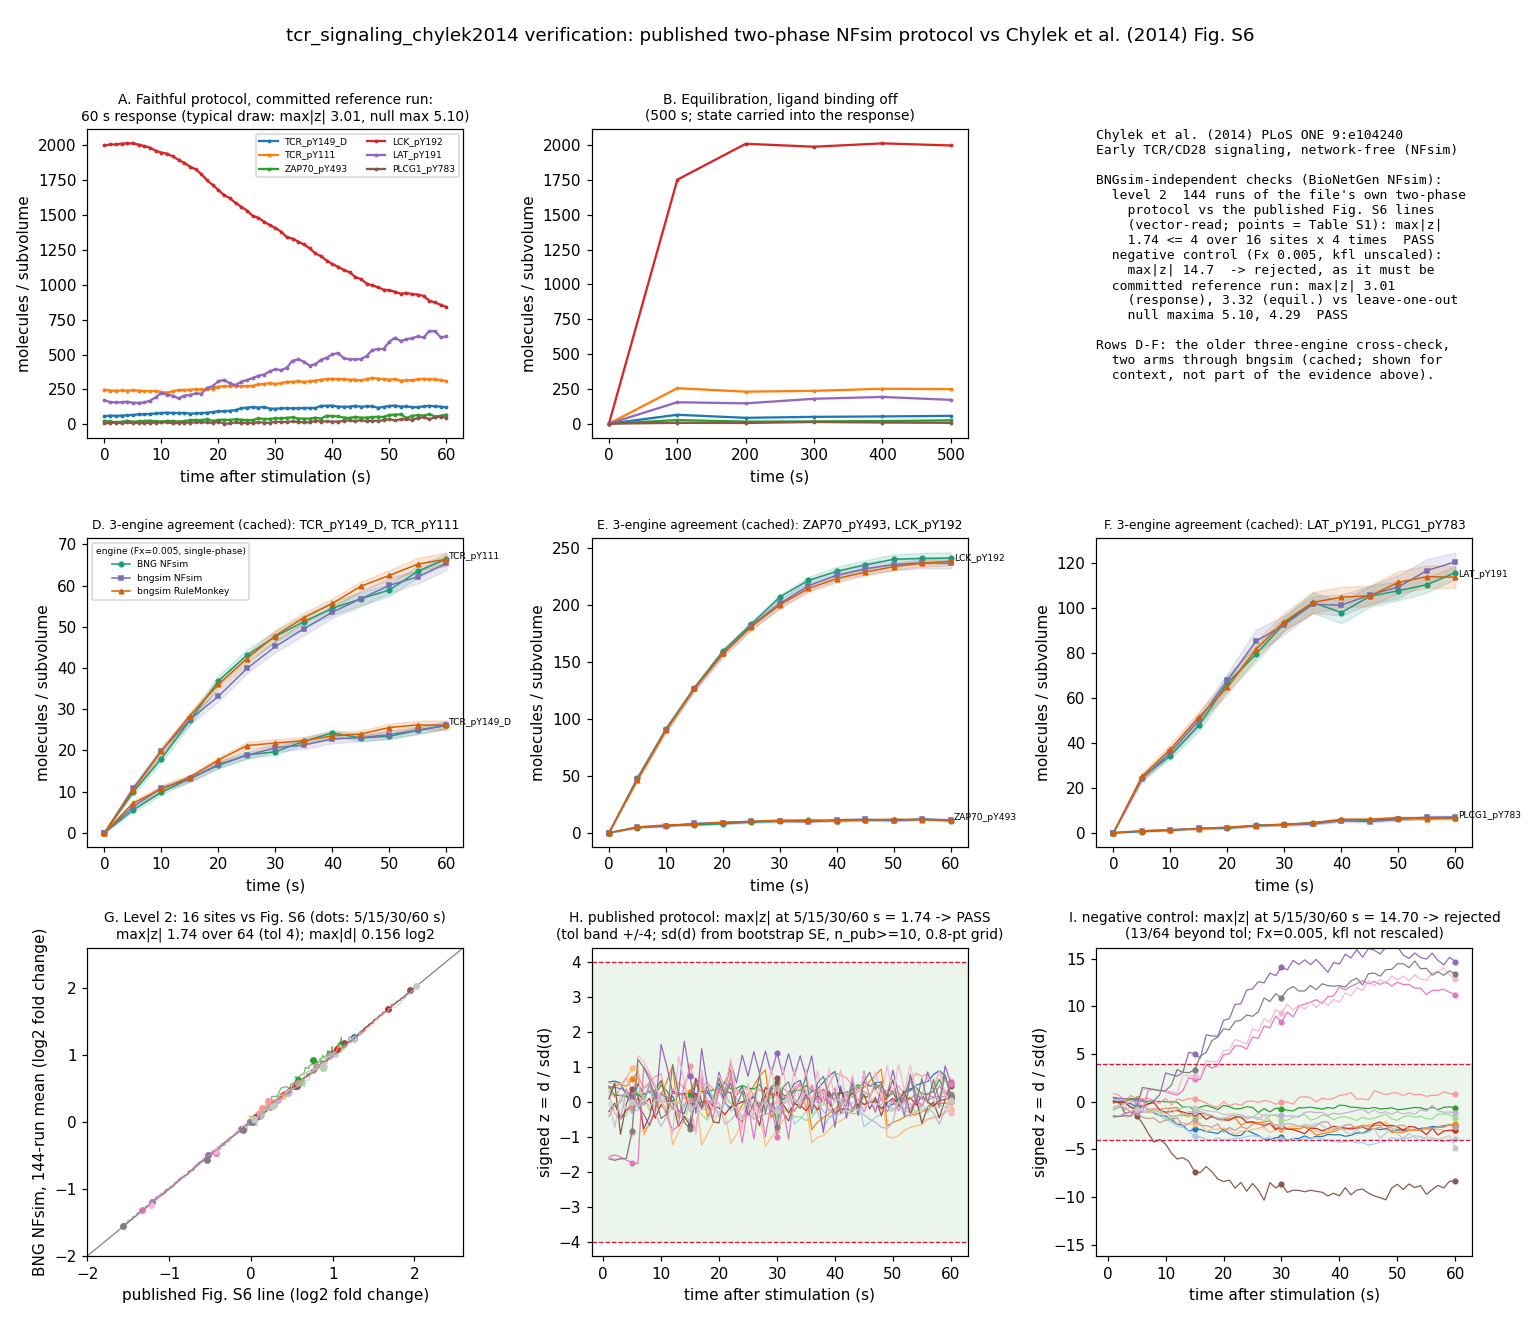

In [9]:
drv.plot()
from IPython.display import Image
Image(filename=os.path.join(drv.HERE, 'verify_tcr_chylek2014.png'))

## Conclusions

* **Level 2 passes against the published simulation.** 144 runs of the committed file's own
  two-phase protocol under BioNetGen's NFsim reproduce all 16 Fig. S6 lines at the four
  measurement times within the stated error budget (see the numbers above), and the
  same check rejects a 4x-slow ligand-binding variant by a wide margin.
* **The published numbers are recovered exactly.** Fig. S6 is read as vector geometry and its
  measured points agree with the authors' Table S1 to the PDF's 0.8-pt grid in 15 of 16
  panels; panel h ("LCK Y424", Table S1's LCK 394) is the one that does not, by two grid steps.
* **The committed reference run is a typical draw** from the same ensemble.
* All of this runs through BNG2.pl's NFsim (default flags: `-cb`, no `-bscb`); no bngsim.